# Prestige Constructions — Construction Progress & Cost Forecasting

This notebook builds and evaluates a machine-learning forecasting model on the
**synthetic** construction progress & cost dataset generated earlier (18
residential projects across 6 cities, 2 years of daily data). It:

1. Explores the data (progress curves, cost breakdown, delays, weather effects)
2. Engineers features for a one-step-ahead ("predict tomorrow from today")
   forecasting model
3. Trains and evaluates two RandomForest models — one for daily construction
   progress, one for daily cost incurred
4. Backtests the model by recursively forecasting a hidden holdout window and
   comparing it to what actually happened
5. Produces a live forward forecast (with Monte Carlo uncertainty bands) for
   an in-progress project, including a cost-at-completion vs. budget check
6. Saves the trained models so the companion Streamlit app (`app.py`) can
   load them directly

> **Note:** every number in this dataset is synthetic (see
> `data/README_data_dictionary.md`). The point of this notebook is to
> demonstrate a complete, reusable forecasting pipeline — swap in your real
> project data with the same column names and everything downstream keeps working.


In [1]:
import sys
sys.path.insert(0, '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import forecasting_lib as fl

%matplotlib inline
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

pd.set_option('display.max_columns', 60)


## 1. Load data

In [2]:
data = fl.load_data('data')
projects, progress, cost_breakdown, milestones = (
    data['projects'], data['progress'], data['cost_breakdown'], data['milestones']
)
for name, df in data.items():
    print(f"{name:16s} {df.shape}")
projects[['project_id','project_name','city','project_type','total_units',
          'approved_budget_cr','revised_budget_cr','status_as_of_today']].head(10)


projects         (18, 19)
progress         (9849, 16)
cost_breakdown   (49245, 4)
milestones       (72, 5)


,project_id,project_name,city,project_type,total_units,approved_budget_cr,revised_budget_cr,status_as_of_today
0,PRJ001,Prestige Skyline,Bengaluru,High-rise Apartments,962,374.85,457.317,Ongoing
1,PRJ002,Prestige Emerald Woods,Bengaluru,High-rise Apartments,622,200.22,231.254,Ongoing
2,PRJ003,Prestige Metro Heights,Bengaluru,Premium Apartments,1019,282.35,297.597,Ongoing
3,PRJ004,Prestige Lakeview,Bengaluru,High-rise Apartments,195,92.38,104.482,Ongoing
4,PRJ005,Prestige Palm Meadows,Bengaluru,Premium Apartments,286,103.15,126.359,Ongoing
5,PRJ006,Prestige Green Valley,Bengaluru,Premium Apartments,452,155.63,186.289,Completed
6,PRJ007,Prestige Silver Oaks,Chennai,Premium Apartments,631,138.92,168.649,Ongoing
7,PRJ008,Prestige Golden Crest,Chennai,Premium Apartments,731,247.96,307.222,Ongoing
8,PRJ009,Prestige Botanica,Chennai,High-rise Apartments,211,105.19,117.182,Ongoing
9,PRJ010,Prestige Willow Park,Hyderabad,High-rise Apartments,325,102.13,106.522,Completed


## 2. Exploratory data analysis

**Portfolio status as of the last day in the dataset:**

In [3]:
projects['status_as_of_today'].value_counts()


status_as_of_today
Ongoing      14
Completed     4
Name: count, dtype: int64

**Planned vs. actual progress for a handful of projects** — this is the core signal the forecasting model needs to learn: how far actual execution drifts from the original S-curve schedule.

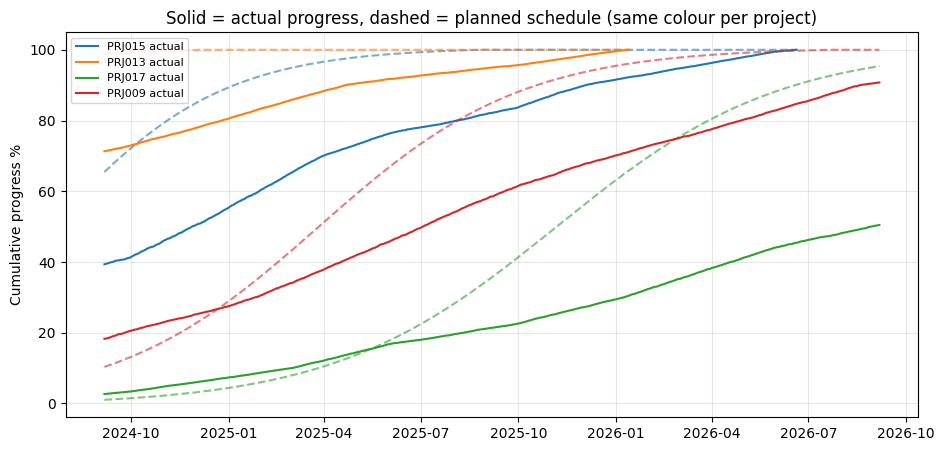

In [4]:
sample_ids = projects['project_id'].sample(4, random_state=7).tolist()

fig, ax = plt.subplots(figsize=(11, 5))
for pid in sample_ids:
    g = progress[progress.project_id == pid].sort_values('date')
    line, = ax.plot(g['date'], g['actual_progress_pct'], label=f"{pid} actual")
    ax.plot(g['date'], g['planned_progress_pct'], linestyle='--', color=line.get_color(), alpha=0.6)
ax.set_title('Solid = actual progress, dashed = planned schedule (same colour per project)')
ax.set_ylabel('Cumulative progress %')
ax.legend(loc='upper left', fontsize=8)
plt.show()


**Cost incurred by category, portfolio-wide** — sanity-checks that the cost breakdown fact table reconciles with the main progress fact table's daily cost.

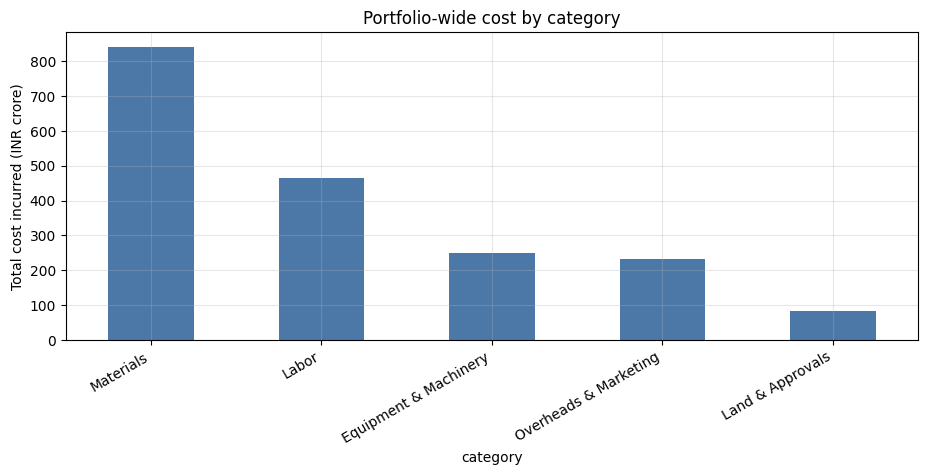

Reconciliation check (should be ~0): 0.08 lakhs


In [5]:
cat_totals = cost_breakdown.groupby('category')['cost_incurred_lakhs'].sum().sort_values(ascending=False)
cat_totals_cr = cat_totals / 100
ax = cat_totals_cr.plot(kind='bar', color='#4C78A8')
ax.set_ylabel('Total cost incurred (INR crore)')
ax.set_title('Portfolio-wide cost by category')
plt.xticks(rotation=30, ha='right')
plt.show()

reconciled_diff = (
    progress.groupby(['date','project_id'])['daily_cost_incurred_lakhs'].sum().sum()
    - cost_breakdown['cost_incurred_lakhs'].sum()
)
print(f"Reconciliation check (should be ~0): {reconciled_diff:.2f} lakhs")


**Delay events** — frequency by reason, and how progress increments drop on delay days vs. normal days.

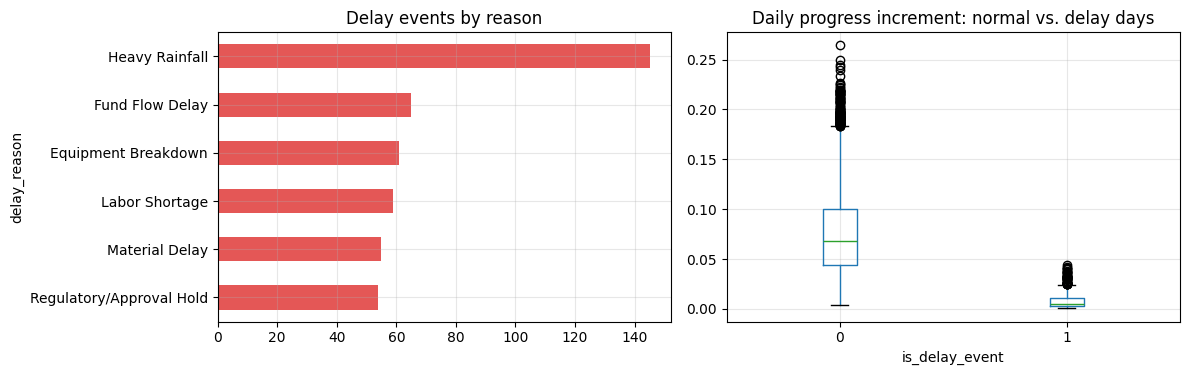

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

progress[progress.is_delay_event == 1]['delay_reason'].value_counts().plot(
    kind='barh', ax=axes[0], color='#E45756'
)
axes[0].set_title('Delay events by reason')
axes[0].invert_yaxis()

progress.boxplot(column='daily_progress_increment_pct', by='is_delay_event', ax=axes[1])
axes[1].set_title('Daily progress increment: normal vs. delay days')
axes[1].set_xlabel('is_delay_event')
plt.suptitle('')
plt.tight_layout()
plt.show()


**Rainfall vs. progress** — confirms the monsoon slowdown baked into the simulator shows up as a learnable pattern.

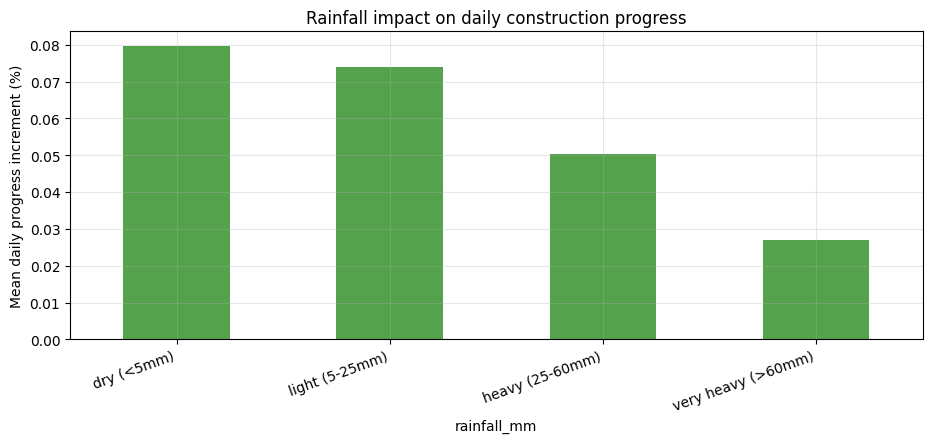

In [7]:
rain_bucket = pd.cut(progress['rainfall_mm'], [-0.1, 5, 25, 60, 1000],
                      labels=['dry (<5mm)', 'light (5-25mm)', 'heavy (25-60mm)', 'very heavy (>60mm)'])
progress.groupby(rain_bucket, observed=True)['daily_progress_increment_pct'].mean().plot(
    kind='bar', color='#54A24B'
)
plt.ylabel('Mean daily progress increment (%)')
plt.title('Rainfall impact on daily construction progress')
plt.xticks(rotation=20, ha='right')
plt.show()


## 3. Feature engineering

We frame this as a **one-step-ahead** forecasting problem: given everything known
up to and including day *t* for a project (lagged/rolling progress and cost,
workers on site, rainfall, macro material prices, delay history, calendar
features, and static project attributes), predict what happens on day *t+1*.

Two important exclusions from the feature set (see `NON_FEATURE_COLS` in
`forecasting_lib.py`): `mgmt_quality_factor` and `overrun_factor` are latent
parameters used only to *generate* the synthetic data — a real deployment
would never have access to them, so including them would leak the answer and
make the model look artificially perfect. Any horizon beyond one day is
reached by feeding a prediction back in as next day's lagged input
(`forecast_project` in `forecasting_lib.py`), which is what section 6 does.


In [8]:
feat = fl.build_feature_table(progress, projects)
feature_cols = fl.get_feature_columns(feat)
print(f"{feat.shape[0]} project-days, {len(feature_cols)} features")
feat[['date','project_id','actual_progress_pct','daily_progress_increment_pct',
      'target_next_increment_pct','target_next_cost_lakhs']].head()


9831 project-days, 53 features


,date,project_id,actual_progress_pct,daily_progress_increment_pct,target_next_increment_pct,target_next_cost_lakhs
0,2025-09-05,PRJ001,0.030,0.0296,0.0384,14.05
1,2025-09-06,PRJ001,0.068,0.0384,0.0140,4.93
2,2025-09-07,PRJ001,0.082,0.0140,0.0260,11.39
3,2025-09-08,PRJ001,0.108,0.0260,0.0329,14.18
4,2025-09-09,PRJ001,0.141,0.0329,0.0370,17.72


## 4. Train / test split

A **time-based** split: the last 90 days of the 2-year window (across all
projects) are held out as test data, everything earlier is used for training.
This mimics real deployment — you only ever have the past to train on — and
avoids the leakage a random row-wise split would introduce (adjacent days
from the same project are highly correlated).


In [9]:
train, test = fl.time_split(feat, test_days=90)
print(f"train: {train.shape[0]} rows, up to {train['date'].max().date()}")
print(f"test:  {test.shape[0]} rows, {test['date'].min().date()} .. {test['date'].max().date()}")

X_train, X_test = train[feature_cols], test[feature_cols]


train: 8495 rows, up to 2026-06-07
test:  1336 rows, 2026-06-08 .. 2026-09-05


## 5. Train the models

In [10]:
progress_model = fl.train_rf(X_train, train['target_next_increment_pct'], n_estimators=300)
progress_metrics = fl.evaluate(progress_model, X_test, test['target_next_increment_pct'])
print('Progress model (next-day % increment) — test metrics:')
progress_metrics


Progress model (next-day % increment) — test metrics:


{'mae': 0.016699778181484073,
 'rmse': 0.02172237349077106,
 'r2': 0.4858744433242681,
 'n': 1336}

In [11]:
cost_model = fl.train_rf(X_train, train['target_next_cost_lakhs'], n_estimators=300)
cost_metrics = fl.evaluate(cost_model, X_test, test['target_next_cost_lakhs'])
print('Cost model (next-day cost incurred, INR lakh) — test metrics:')
cost_metrics


Cost model (next-day cost incurred, INR lakh) — test metrics:


{'mae': 5.3351915426322885,
 'rmse': 7.507857585938176,
 'r2': 0.6548360634154973,
 'n': 1336}

**Feature importance** — what's driving each model's predictions.

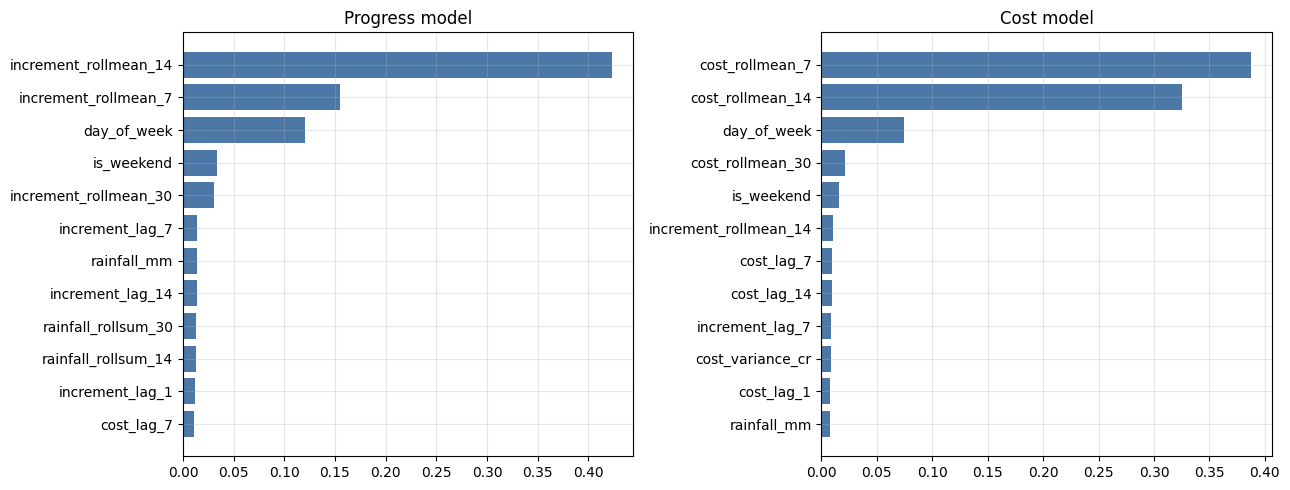

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, model, title in [(axes[0], progress_model, 'Progress model'),
                          (axes[1], cost_model, 'Cost model')]:
    imp = fl.feature_importance(model, feature_cols, top_n=12)
    ax.barh(imp['feature'], imp['importance'], color='#4C78A8')
    ax.invert_yaxis()
    ax.set_title(title)
plt.tight_layout()
plt.show()


**Actual vs. predicted on the held-out test set** — a well-calibrated model should scatter tightly around the diagonal.

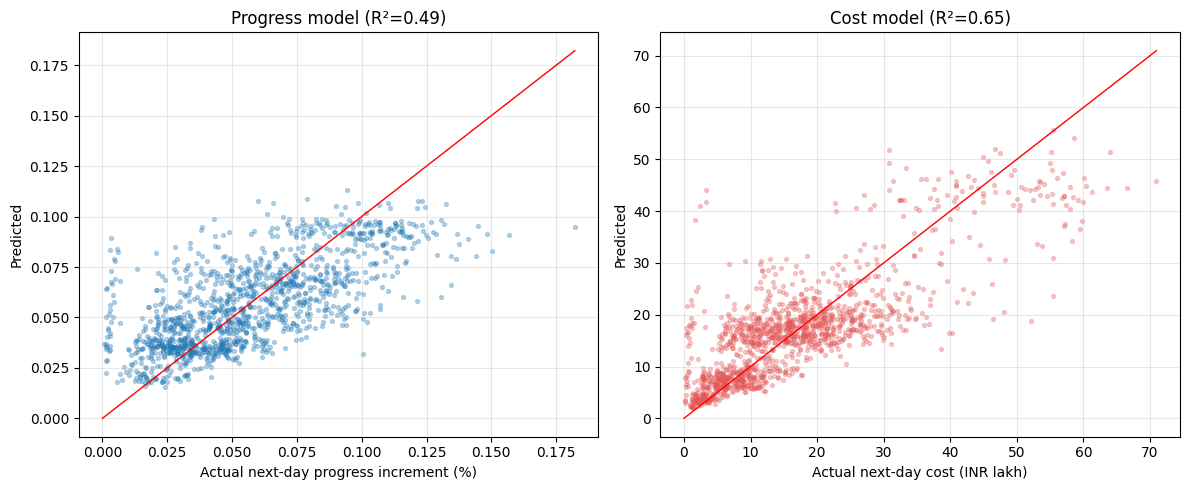

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(test['target_next_increment_pct'], progress_model.predict(X_test), s=8, alpha=0.3)
lims = [0, test['target_next_increment_pct'].max()]
axes[0].plot(lims, lims, color='red', linewidth=1)
axes[0].set_xlabel('Actual next-day progress increment (%)')
axes[0].set_ylabel('Predicted')
axes[0].set_title(f"Progress model (R²={progress_metrics['r2']:.2f})")

axes[1].scatter(test['target_next_cost_lakhs'], cost_model.predict(X_test), s=8, alpha=0.3, color='#E45756')
lims = [0, test['target_next_cost_lakhs'].max()]
axes[1].plot(lims, lims, color='red', linewidth=1)
axes[1].set_xlabel('Actual next-day cost (INR lakh)')
axes[1].set_ylabel('Predicted')
axes[1].set_title(f"Cost model (R²={cost_metrics['r2']:.2f})")

plt.tight_layout()
plt.show()


## 6. Backtest: recursive multi-day forecast vs. what actually happened

The metrics above are all **one-day-ahead** — useful, but the real test of a
forecasting model is whether it stays on track over many days when its own
predictions feed back in as next day's inputs. Here we pick a project, hide
its last 60 days, forecast them recursively from the day before, and compare
the forecast to what the simulator actually generated.


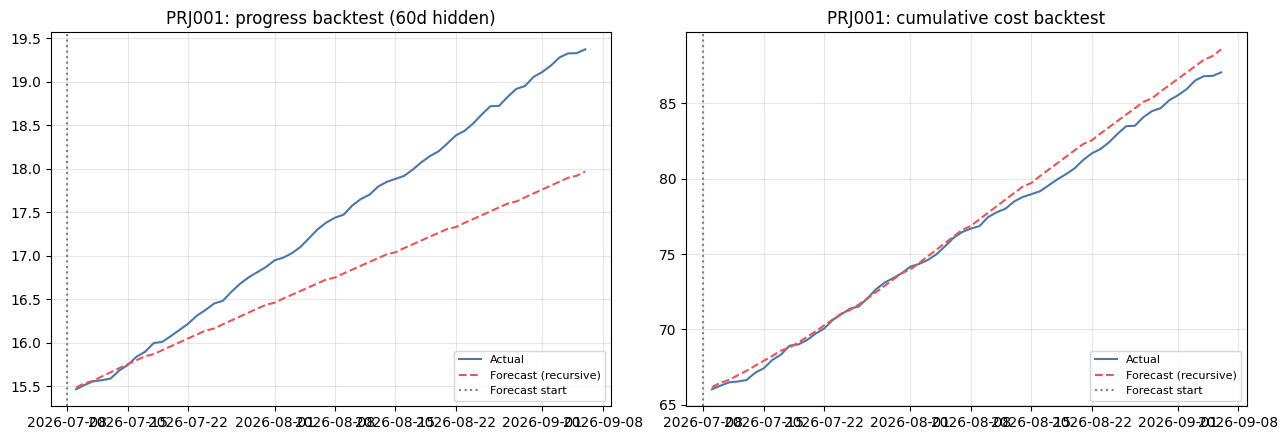

After 60 hidden days — actual progress: 19.4%, recursively forecast: 18.0% (error: -1.4 pts)


In [14]:
# Pick a project with enough history to hide 60 days and still have a
# reasonable amount of training history before the cut.
long_projects = progress.groupby('project_id').size()
backtest_pid = long_projects[long_projects > 300].index[0]

HOLDOUT_DAYS = 60
full_hist = progress[progress.project_id == backtest_pid].sort_values('date').reset_index(drop=True)
cutoff_idx = len(full_hist) - HOLDOUT_DAYS
visible_hist = full_hist.iloc[:cutoff_idx]
actual_holdout = full_hist.iloc[cutoff_idx:]

# Rebuild a progress/cost history dict where this project's "history" stops early,
# so forecast_project only sees data up to the cutoff.
progress_for_backtest = pd.concat([
    progress[progress.project_id != backtest_pid],
    visible_hist
], ignore_index=True)

cfg = fl.ForecastConfig(horizon_days=HOLDOUT_DAYS, n_simulations=1)
bt_forecast = fl.forecast_project(
    backtest_pid, progress_for_backtest, projects, progress_model, cost_model, feature_cols, cfg
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(actual_holdout['date'], actual_holdout['actual_progress_pct'], label='Actual', color='#4C78A8')
axes[0].plot(bt_forecast['date'], bt_forecast['forecast_progress_pct'], label='Forecast (recursive)',
             color='#E45756', linestyle='--')
axes[0].axvline(visible_hist['date'].iloc[-1], color='gray', linestyle=':', label='Forecast start')
axes[0].set_title(f'{backtest_pid}: progress backtest ({HOLDOUT_DAYS}d hidden)')
axes[0].legend(fontsize=8)

axes[1].plot(actual_holdout['date'], actual_holdout['cumulative_cost_incurred_cr'], label='Actual', color='#4C78A8')
axes[1].plot(bt_forecast['date'], bt_forecast['forecast_cumulative_cost_cr'], label='Forecast (recursive)',
             color='#E45756', linestyle='--')
axes[1].axvline(visible_hist['date'].iloc[-1], color='gray', linestyle=':', label='Forecast start')
axes[1].set_title(f'{backtest_pid}: cumulative cost backtest')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

end_actual = actual_holdout['actual_progress_pct'].iloc[-1]
end_forecast = bt_forecast['forecast_progress_pct'].iloc[-1]
print(f"After {HOLDOUT_DAYS} hidden days — actual progress: {end_actual:.1f}%, "
      f"recursively forecast: {end_forecast:.1f}% (error: {end_forecast-end_actual:+.1f} pts)")


## 7. Live forward forecast with Monte Carlo uncertainty

For an actually-ongoing project, forecast forward from *today* (the last real
data point) rather than from a hidden past date. Running many randomised
simulations (varying day-to-day noise and delay-event risk, drawn from the
model's own residuals and the historical delay rate) gives a p10–p90 band
instead of one brittle line — and lets us flag whether the project is on
track to finish within budget.


Forecasting: PRJ016 — Prestige Cedar Springs (Mumbai)


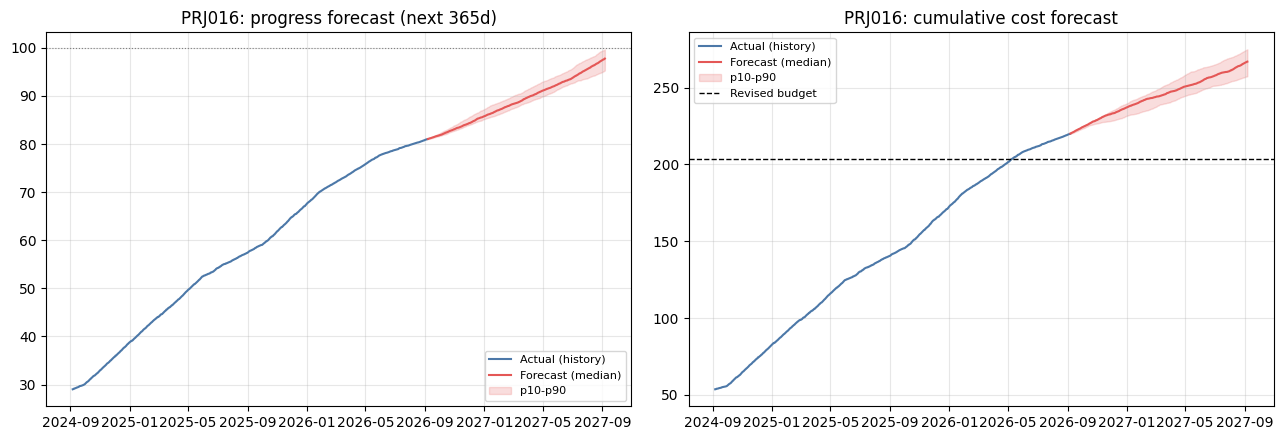

Project not forecast to complete within the 365-day horizon.


In [15]:
ongoing = projects[projects.status_as_of_today == 'Ongoing'].copy()
ongoing['days_elapsed'] = (progress['date'].max() - ongoing['actual_start_date']).dt.days
target_pid = ongoing.sort_values('days_elapsed', ascending=False).iloc[0]['project_id']
proj_row = projects[projects.project_id == target_pid].iloc[0]
print(f"Forecasting: {target_pid} — {proj_row['project_name']} ({proj_row['city']})")

cfg = fl.ForecastConfig(
    horizon_days=365,
    n_simulations=30,
    residual_std_increment=progress_metrics['rmse'],
    residual_std_cost=cost_metrics['rmse'],
)
forward = fl.forecast_project(target_pid, progress, projects, progress_model, cost_model, feature_cols, cfg)
band = fl.summarise_forecast(forward)

hist = progress[progress.project_id == target_pid].sort_values('date')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(hist['date'], hist['actual_progress_pct'], color='#4C78A8', label='Actual (history)')
axes[0].plot(band['date'], band['progress_p50'], color='#E45756', label='Forecast (median)')
axes[0].fill_between(band['date'], band['progress_p10'], band['progress_p90'], color='#E45756', alpha=0.2, label='p10-p90')
axes[0].axhline(100, color='gray', linewidth=0.8, linestyle=':')
axes[0].set_title(f'{target_pid}: progress forecast (next {cfg.horizon_days}d)')
axes[0].legend(fontsize=8)

axes[1].plot(hist['date'], hist['cumulative_cost_incurred_cr'], color='#4C78A8', label='Actual (history)')
axes[1].plot(band['date'], band['cost_p50'], color='#E45756', label='Forecast (median)')
axes[1].fill_between(band['date'], band['cost_p10'], band['cost_p90'], color='#E45756', alpha=0.2, label='p10-p90')
axes[1].axhline(proj_row['revised_budget_cr'], color='black', linewidth=1, linestyle='--', label='Revised budget')
axes[1].set_title(f'{target_pid}: cumulative cost forecast')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

completion_row = band[band['progress_p50'] >= 99.9]
if len(completion_row):
    eta = completion_row.iloc[0]['date']
    cost_at_completion = completion_row.iloc[0]['cost_p50']
    print(f"Median forecast completion date: {eta.date()}")
    print(f"Forecast cost at completion: INR {cost_at_completion:.1f} cr "
          f"vs. revised budget INR {proj_row['revised_budget_cr']:.1f} cr "
          f"({'OVER' if cost_at_completion > proj_row['revised_budget_cr'] else 'within'} budget)")
else:
    print(f"Project not forecast to complete within the {cfg.horizon_days}-day horizon.")


## 8. Save trained models for the Streamlit app

Persists both models, the feature column list, and evaluation metrics
(including test-set residual std, used to calibrate the app's Monte Carlo
bands) to `models/`, which `app.py` loads on startup.


In [16]:
metrics = {
    'progress_model': progress_metrics,
    'cost_model': cost_metrics,
    'residual_std_increment': float(np.std(progress_model.predict(X_test) - test['target_next_increment_pct'])),
    'residual_std_cost': float(np.std(cost_model.predict(X_test) - test['target_next_cost_lakhs'])),
    'test_days': 90,
    'n_features': len(feature_cols),
}
fl.save_artifacts('models', progress_model, cost_model, feature_cols, metrics)
print('Saved progress_model.joblib, cost_model.joblib, feature_cols.json, metrics.json to ./models/')


Saved progress_model.joblib, cost_model.joblib, feature_cols.json, metrics.json to ./models/


## 9. Summary & next steps

- The progress model explains a moderate share of day-to-day variance
  (R² ≈ 0.5) — expected, since daily progress genuinely is noisy (weather,
  random stoppages), and the model correctly leans on recent momentum
  (`increment_rollmean_7/14`) and calendar effects (weekday/weekend).
- The cost model is more predictable (R² ≈ 0.65) since cost tracks physical
  progress fairly directly.
- The recursive backtest in section 6 is the more meaningful check: it shows
  whether errors compound over a multi-week horizon or stay bounded.
- **To use this on real data:** replace the four CSVs in `data/` with real
  exports using the same schema (see `data/README_data_dictionary.md`), rerun
  this notebook (or `train_and_save_models.py`), and the Streamlit app will
  pick up the freshly trained models automatically.
- **Possible extensions:** gradient boosting (XGBoost/LightGBM) for a
  potential accuracy bump, quantile regression for sharper uncertainty bands,
  a classifier for delay-event risk, or per-project models if the portfolio
  grows large enough to warrant it.
